# Unit III: Data Cleaning and Preparation

**Syllabus:** types of attributes, data sources and data quality, data cleaning, identifying outliers, measures of centre
and spread, data exploration (hypothesis testing vs exploratory data analysis), data transformation, structural inspection,
data encoding.

This is the unit TaskClean is *about*, so the cleaning section reuses the project's own detectors (`detect_missing`,
`detect_duplicates`, `detect_outliers_iqr` from `src/detect.py`, imported read-only) on a dataset where we **know the truth**
because we damage it ourselves, in memory, on a copy.

In [1]:
import sys, pathlib
for _p in (pathlib.Path.cwd(), pathlib.Path.cwd() / "notebooks"):   # works from notebooks/ or the project root
    if (_p / "common.py").exists():
        sys.path.insert(0, str(_p)); break
from common import *
df = load_adult()
print(f"{df.shape[0]:,} rows x {df.shape[1]} columns (UCI Adult, natively-missing rows dropped)")

45,222 rows x 15 columns (UCI Adult, natively-missing rows dropped)


## 3.1 Structural inspection

Before any statistics, inspect the *structure*: how many rows and columns, what type each column has, how much memory it
uses, whether anything is constant, duplicated, or hides a missing-value placeholder (`?`, `N/A`, `-`, empty text).
`df.info()` is the one-call summary.

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45222 entries, 0 to 45221
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   age             45222 non-null  int64   
 1   workclass       45222 non-null  category
 2   fnlwgt          45222 non-null  int64   
 3   education       45222 non-null  category
 4   education-num   45222 non-null  int64   
 5   marital-status  45222 non-null  category
 6   occupation      45222 non-null  category
 7   relationship    45222 non-null  category
 8   race            45222 non-null  category
 9   sex             45222 non-null  category
 10  capital-gain    45222 non-null  int64   
 11  capital-loss    45222 non-null  int64   
 12  hours-per-week  45222 non-null  int64   
 13  native-country  45222 non-null  category
 14  class           45222 non-null  category
dtypes: category(9), int64(6)
memory usage: 2.5 MB


In [3]:
checks = {
    "rows x columns": f"{df.shape[0]:,} x {df.shape[1]}",
    "memory (MB, deep)": round(df.memory_usage(deep=True).sum() / 1e6, 2),
    "columns with only one value (constant)": [c for c in df.columns if df[c].nunique() == 1],
    "exact duplicate rows": int(df.duplicated().sum()),
    "missing cells (NaN)": int(df.isna().sum().sum()),
    "'?' placeholders in text columns": int(sum((df[c].astype(str).str.strip() == "?").sum() for c in df.columns if df[c].dtype.name == "category")),
    "text values with leading/trailing spaces": int(sum((df[c].astype(str) != df[c].astype(str).str.strip()).sum() for c in df.columns if df[c].dtype.name == "category")),
}
pd.Series(checks, name="result").to_frame()

,result
rows x columns,"45,222 x 15"
"memory (MB, deep)",2.58
columns with only one value (constant),[]
exact duplicate rows,47
missing cells (NaN),0
'?' placeholders in text columns,0
text values with leading/trailing spaces,0


The project's Adult file has **no missing cells and no placeholders** because rows with a `?` were dropped when the file was
prepared (the research needed a zero-defect starting point to inject known errors into). That is itself a cleaning *decision*
with a cost: it removed about 7% of the original rows, and in the raw census data the missing values are concentrated in
`workclass`, `occupation` and `native-country`, i.e. they are *not* random, so dropping them can bias the sample. 47 exact
duplicate rows do remain (shown above); they are real (two different people can have identical answers), which is why duplicate removal
needs care.

## 3.2 Data sources and data quality

Data quality is judged along several **dimensions**. Each can be turned into a *rule* that is checked automatically:

| Dimension | Question | Rule used below |
|---|---|---|
| Completeness | are values missing? | count of missing cells |
| Uniqueness | are records repeated? | exact duplicate rows |
| Validity | are values in the allowed range/format? | `17 <= age <= 100`, `1 <= hours <= 168`, `capital >= 0`, `sex` in two values |
| Consistency | do related fields agree? | `education` and `education-num` must map one-to-one |
| Plausibility | is the combination believable? | age < 22 with a Master's degree or higher |

*Sources* matter too: this file is **secondary data** (a census extract prepared by others, 1994 US), so you inherit its
sampling choices, its `fnlwgt` weighting, and its age, which a modern analysis must keep in mind.

In [4]:
one_to_one = (df.groupby("education", observed=True)["education-num"].nunique().eq(1).all()
              and df.groupby("education-num")["education"].nunique().eq(1).all())
rules = [
    ("Completeness", "no missing cells",                      int(df.isna().sum().sum())),
    ("Uniqueness",   "no exact duplicate rows",               int(df.duplicated().sum())),
    ("Validity",     "17 <= age <= 100",                      int((~df["age"].between(17, 100)).sum())),
    ("Validity",     "1 <= hours-per-week <= 168",            int((~df["hours-per-week"].between(1, 168)).sum())),
    ("Validity",     "capital-gain and capital-loss >= 0",    int(((df["capital-gain"] < 0) | (df["capital-loss"] < 0)).sum())),
    ("Validity",     "sex has exactly 2 values",              int(df["sex"].nunique() != 2)),
    ("Consistency",  "education <-> education-num one-to-one", int(not one_to_one)),
    ("Plausibility", "not (age < 22 and education-num >= 14)", int(((df["age"] < 22) & (df["education-num"] >= 14)).sum())),
]
report = pd.DataFrame(rules, columns=["dimension", "rule", "violations"])
report["status"] = np.where(report["violations"] == 0, "pass", "REVIEW")
report

,dimension,rule,violations,status
0,Completeness,no missing cells,0,pass
1,Uniqueness,no exact duplicate rows,47,REVIEW
2,Validity,17 <= age <= 100,0,pass
3,Validity,1 <= hours-per-week <= 168,0,pass
4,Validity,capital-gain and capital-loss >= 0,0,pass
5,Validity,sex has exactly 2 values,0,pass
6,Consistency,education <-> education-num one-to-one,0,pass
7,Plausibility,not (age < 22 and education-num >= 14),3,REVIEW


## 3.3 Data cleaning: detect, repair, and check the repair

Real data does not come with the answer key, so to *learn* cleaning we damage a copy in a controlled way and keep the key.
We take a 6,000-row sample and inject, with a fixed seed:
- 5% missing values in each of `age`, `hours-per-week` and `workclass` (900 rows, disjoint),
- 60 **impossible** values (ages 130-200 and weekly hours above 168, i.e. clear data-entry errors),
- 200 appended exact **duplicate** rows.

Because we know which cells we damaged we can grade each detector with **precision** (of what it flagged, how much was truly
damaged) and **recall** (of the truly damaged, how much it found). *(The project's `src/corruption/` engine does this at
scale with full logging; this is a small, readable version.)*

In [5]:
rng = np.random.default_rng(SEED)
base = df.sample(6000, random_state=SEED).reset_index(drop=True)
n = len(base)
dirty = base.copy()
for c in ["age", "hours-per-week"]:
    dirty[c] = dirty[c].astype(float)             # pandas 3 will not store NaN/floats in an int column silently

perm = rng.permutation(n)                          # disjoint row sets, so every damaged cell has exactly one cause
miss_age, miss_hours, miss_work = perm[:300], perm[300:600], perm[600:900]
bad_age, bad_hours = perm[900:930], perm[930:960]
dirty.loc[miss_age, "age"] = np.nan
dirty.loc[miss_hours, "hours-per-week"] = np.nan
dirty.loc[miss_work, "workclass"] = np.nan
dirty.loc[bad_age, "age"] = rng.integers(130, 200, size=len(bad_age))
dirty.loc[bad_hours, "hours-per-week"] = rng.integers(170, 400, size=len(bad_hours))
dup_src = rng.choice(perm[1000:], 200, replace=False)
dirty = pd.concat([dirty, dirty.iloc[dup_src]], ignore_index=True)

truth = {"missing rows": np.isin(dirty.index, perm[:900]),
         "impossible-age rows": np.isin(dirty.index, bad_age),
         "impossible-value rows": np.isin(dirty.index, perm[900:960]),
         "duplicate rows": dirty.index >= n}
print(f"base {base.shape} -> dirty {dirty.shape};  injected rows: " + ", ".join(f"{k} {v.sum()}" for k, v in truth.items()))

base (6000, 15) -> dirty (6200, 15);  injected rows: missing rows 900, impossible-age rows 30, impossible-value rows 60, duplicate rows 200


In [6]:
from detect import detect_missing, detect_duplicates, detect_outliers_iqr

def grade(flag, true):
    flag, true = np.asarray(flag, bool), np.asarray(true, bool)
    tp = (flag & true).sum()
    return {"flagged": int(flag.sum()), "truly damaged": int(true.sum()),
            "precision": tp / max(flag.sum(), 1), "recall": tp / max(true.sum(), 1)}

domain_rule = (dirty["age"] > 100) | (dirty["hours-per-week"] > 168)       # physically impossible values
results = pd.DataFrame({
    "missing (detect_missing)":                          grade(detect_missing(dirty).row_mask, truth["missing rows"]),
    "duplicates (detect_duplicates)":                    grade(detect_duplicates(dirty).row_mask, truth["duplicate rows"]),
    "outliers: IQR rule on age only (vs the 30 bad ages)": grade(detect_outliers_iqr(dirty[["age"]]).row_mask, truth["impossible-age rows"]),
    "outliers: IQR rule on age + hours (vs all 60)":     grade(detect_outliers_iqr(dirty[["age", "hours-per-week"]]).row_mask, truth["impossible-value rows"]),
    "outliers: domain rule (vs all 60)":                 grade(domain_rule, truth["impossible-value rows"]),
}).T
results.round(3)

,flagged,truly damaged,precision,recall
missing (detect_missing),900.0,900.0,1.000,1.0
duplicates (detect_duplicates),201.0,200.0,0.995,1.0
outliers: IQR rule on age only (vs the 30 bad ages),73.0,30.0,0.411,1.0
outliers: IQR rule on age + hours (vs all 60),1603.0,60.0,0.037,1.0
outliers: domain rule (vs all 60),60.0,60.0,1.000,1.0


**What this teaches (read the table above).**
- *Missing values* and *exact duplicates* are found essentially perfectly; they are *structural* defects. (Precision for
  duplicates is just under 1 because the real data already contains a handful of genuine duplicate rows, which the detector
  correctly flags but we did not inject.)
- The **IQR rule on `age` alone** finds every one of the 30 impossible ages (recall 1.0) but also flags real old people
  (ages above the fence of 76), so only about 4 in 10 flags are real errors. Adding `hours-per-week` makes precision collapse: most people work exactly 40 hours, the IQR is tiny, and a quarter
  of *normal* rows fall outside the fences (see 2.4). A statistical rule cannot know that 60 or 80 hours is plausible.
- The **domain rule** is perfect here, but only because we injected *impossible* values. Real outliers (a 90-year-old, an
  80-hour week) are usually *plausible*, and then no automatic rule can tell error from truth: that is the heart of the
  project's finding that "detected" is not the same as "safe to repair".

In [7]:
# Repair: remove duplicates, turn impossible values into missing, then impute (median for numbers, mode for categories)
clean = dirty.drop_duplicates(keep="first").copy()
clean.loc[clean["age"] > 100, "age"] = np.nan
clean.loc[clean["hours-per-week"] > 168, "hours-per-week"] = np.nan
for col in ["age", "hours-per-week"]:
    clean[col] = clean[col].fillna(clean[col].median())
clean["workclass"] = clean["workclass"].fillna(clean["workclass"].mode().iloc[0])

def summary(frame, label):
    return {"rows": len(frame), "missing cells": int(frame.isna().sum().sum()), "duplicates": int(frame.duplicated().sum()),
            "age mean": frame["age"].mean(), "age std": frame["age"].std(), "age max": frame["age"].max(),
            "hours mean": frame["hours-per-week"].mean(), "hours std": frame["hours-per-week"].std(), "hours max": frame["hours-per-week"].max()}

comparison = pd.DataFrame({"original sample (truth)": summary(base, ""), "dirty": summary(dirty, ""), "after cleaning": summary(clean, "")}).round(2)
comparison

,original sample (truth),dirty,after cleaning
rows,6000.00,6200.00,5999.00
missing cells,0.00,900.00,0.00
duplicates,1.00,201.00,0.00
age mean,38.46,39.15,38.41
age std,13.31,15.93,12.91
age max,90.00,196.00,90.00
hours mean,40.76,41.91,40.71
hours std,12.00,20.93,11.69
hours max,99.00,391.00,99.00


In [8]:
# How good is the repair on the cells we know the truth for?  (age cells that were missing or impossible)
bad_cells = np.concatenate([miss_age, bad_age])
true_age = base.loc[bad_cells, "age"].to_numpy(dtype=float)
repaired_age = clean.loc[bad_cells, "age"].to_numpy(dtype=float)
print(f"Median-imputed ages vs the real ages: mean absolute error = {np.abs(repaired_age - true_age).mean():.1f} years, "
      f"almost as large as the spread of ages itself (std = {base['age'].std():.1f}), because a single fill value uses no information about the person")
print(f"Spread of age: original {base['age'].std():.2f} -> cleaned {clean['age'].std():.2f}  "
      "(imputing one value for many rows shrinks the variance: cleaned data looks more uniform than reality)")
print("Remaining issues by the project's own detectors:",
      f"missing {int(detect_missing(clean).row_mask.sum())}, duplicates {int(detect_duplicates(clean).row_mask.sum())}")

Median-imputed ages vs the real ages: mean absolute error = 11.5 years, almost as large as the spread of ages itself (std = 13.3), because a single fill value uses no information about the person
Spread of age: original 13.31 -> cleaned 12.91  (imputing one value for many rows shrinks the variance: cleaned data looks more uniform than reality)
Remaining issues by the project's own detectors: missing 0, duplicates 0


**The cleaning trade-off in numbers.** After cleaning, the defects are gone and the mean is back close to the truth, but
*every* imputed cell now holds the same value, so the standard deviation shrank. The repaired column is easier to model but
*less honest*. This is why TaskClean measures whether a repair actually helps a downstream model instead of assuming that a
cleaner-looking table is a better one.

## 3.4 Identifying outliers, and why centre and spread matter

An **outlier** is a value far from the rest. Three standard rules (all in this notebook or the project):

| Rule | Flags a value if | Assumes |
|---|---|---|
| **z-score** | `abs(x - mean) / std > 3` | roughly normal data; but the mean and std are themselves pulled by outliers |
| **Tukey / IQR** | outside `[Q1 - 1.5 IQR, Q3 + 1.5 IQR]` | none; uses quartiles, so it is robust |
| **Percentile / winsorising** | beyond the 1st / 99th percentile | none; always flags a fixed share |

The choice of **centre and spread** decides how robust you are. One bad value moves the mean and std, but not the median and IQR:

In [9]:
age_dirty = dirty["age"].dropna()
age_true = base["age"]
robust = pd.DataFrame({
    "true ages": [age_true.mean(), age_true.std(), age_true.median(), age_true.quantile(.75) - age_true.quantile(.25)],
    "ages with 30 impossible values": [age_dirty.mean(), age_dirty.std(), age_dirty.median(), age_dirty.quantile(.75) - age_dirty.quantile(.25)],
}, index=["mean", "std dev", "median", "IQR"]).round(2)
robust["change"] = (robust["ages with 30 impossible values"] - robust["true ages"]).round(2)
display(robust)

z = (age_dirty - age_dirty.mean()) / age_dirty.std()
q1, q3 = age_dirty.quantile([.25, .75]); iqr = q3 - q1
lo, hi = age_dirty.quantile([.01, .99])
impossible = age_dirty > 100
flags = {"z-score > 3": z.abs() > 3,
         "Tukey IQR fences": (age_dirty < q1 - 1.5 * iqr) | (age_dirty > q3 + 1.5 * iqr),
         "outside 1st/99th percentile": (age_dirty < lo) | (age_dirty > hi)}
pd.DataFrame({name: {"flagged": int(f.sum()), "of which truly impossible": int((f & impossible).sum()),
                     "false alarms (real ages)": int((f & ~impossible).sum())} for name, f in flags.items()}).T

,true ages,ages with 30 impossible values,change
mean,38.46,39.15,0.69
std dev,13.31,15.93,2.62
median,37.00,37.00,0.00
IQR,19.00,19.00,0.00


,flagged,of which truly impossible,false alarms (real ages)
z-score > 3,39,30,9
Tukey IQR fences,73,30,43
outside 1st/99th percentile,56,30,26


Only 30 bad values out of 5,900 (0.5%) move the mean by about 0.7 years and inflate the std dev by about 2.6 years (roughly
20% larger), while the median and IQR do not change at all. In the second table all three rules catch the 30 impossible ages,
but they differ in **false alarms** on genuine (old) people: the z-score rule has the fewest here because these errors are so
extreme, the IQR rule the most. (A z-score threshold is itself computed from the mean and std that the outliers distort, so
with milder errors it can miss them.) The percentile rule flags a fixed share whether or not errors exist, so it is a screening
tool, not a verdict. Always follow a statistical flag with a *domain* check.

## 3.5 Data exploration: hypothesis testing vs exploratory data analysis (EDA)

| | **EDA** | **Hypothesis testing (confirmatory)** |
|---|---|---|
| Goal | *generate* questions: look for patterns | *answer* one question that was fixed in advance |
| Method | plots, summaries, many looks | a pre-stated H0, one test, a p-value |
| Risk | seeing patterns that are only noise | p-values are only valid for hypotheses chosen *before* looking |

The danger is mixing them: look at many groups, pick the most striking one, then "confirm" it on the same data. Two
experiments show the problem and the fix.

**Experiment 1: multiple comparisons.** Shuffle the income labels (so there is *no* real relationship with occupation by
construction) and test each of the 14 occupations against the rest at the 5% level. How often does at least one test look
"significant" anyway?

In [10]:
from scipy import stats

y_bool = (df[TARGET] == ">50K").to_numpy()
occ_codes = df["occupation"].cat.codes.to_numpy()
k = df["occupation"].cat.categories.size
tot = np.bincount(occ_codes, minlength=k)

def occupation_pvalues(y):
    pos = np.bincount(occ_codes, weights=y, minlength=k)
    P, N = pos.sum(), len(y)
    ps = []
    for j in range(k):
        table = [[pos[j], tot[j] - pos[j]], [P - pos[j], (N - tot[j]) - (P - pos[j])]]
        ps.append(stats.chi2_contingency(table, correction=False)[1])
    return np.array(ps)

rng = np.random.default_rng(SEED)
min_p = np.array([occupation_pvalues(rng.permutation(y_bool)).min() for _ in range(200)])
print(f"{k} occupations tested per shuffle, 200 shuffles of the labels (no real effect exists):")
print(f"  share of shuffles with at least one 'significant' occupation (p < 0.05)      : {(min_p < 0.05).mean():.0%}")
print(f"  theory: 1 - 0.95^{k} = {1 - 0.95 ** k:.0%}")
print(f"  after Bonferroni correction (compare min p with 0.05/{k} = {0.05 / k:.4f})        : {(min_p < 0.05 / k).mean():.0%}")

14 occupations tested per shuffle, 200 shuffles of the labels (no real effect exists):
  share of shuffles with at least one 'significant' occupation (p < 0.05)      : 42%
  theory: 1 - 0.95^14 = 51%
  after Bonferroni correction (compare min p with 0.05/14 = 0.0036)        : 4%


Testing many groups at 5% gives a false "discovery" in a large share of shuffles (roughly 4 in 10 here; the independent-tests
formula predicts 51%, and the tests are not fully independent). Hence: *either* decide the one hypothesis in
advance, *or* correct for the number of looks (Bonferroni: divide the threshold by the number of tests).

**Experiment 2: explore on one half, confirm on the other.** Use half the data (A) for EDA to find a candidate, then test
*only that candidate* on the untouched other half (B).

In [11]:
rng = np.random.default_rng(7)
idx = rng.permutation(len(df))
A, B = df.iloc[idx[: len(df) // 2]], df.iloc[idx[len(df) // 2:]]

# EDA on A: which occupation has the highest share earning >50K? (groups with at least 200 people)
share_A = A.groupby("occupation", observed=True)[TARGET].agg(share=lambda s: (s == ">50K").mean(), n="size").query("n >= 200").sort_values("share", ascending=False)
display(share_A.head(4).round(3))
cand = share_A.index[0]

# Confirmation on B: ONE pre-stated hypothesis -> H0: the candidate occupation earns >50K at the same rate as everyone else
in_group = (B["occupation"] == cand)
table = pd.crosstab(in_group, B[TARGET])
chi2, p, _, _ = stats.chi2_contingency(table, correction=False)
rate = table.loc[True, ">50K"] / table.loc[True].sum(), table.loc[False, ">50K"] / table.loc[False].sum()
print(f"Candidate from EDA on A: '{cand}'.  Test on held-out B: {cand} {rate[0]:.1%} vs everyone else {rate[1]:.1%}, chi2 = {chi2:.1f}, {fmt_p(p)}")

,share,n
occupation,,
Exec-managerial,0.482,3021
Prof-specialty,0.447,2975
Protective-serv,0.323,489
Tech-support,0.284,705


Candidate from EDA on A: 'Exec-managerial'.  Test on held-out B: Exec-managerial 47.7% vs everyone else 21.4%, chi2 = 952.4, p = 4.08e-209


The effect found by EDA **replicates on data that played no part in finding it**, so the p-value is meaningful. That
pattern (explore, then confirm on held-out data) is the same logic as the train/validation/test split used for models in Unit I.

## 3.6 Data transformation

Transformations change the *scale or shape* of an attribute so that methods work better:

- **Normalisation / scaling** (min-max, z-score, robust): put attributes on comparable scales (needed by distance-based and
  gradient-based models).
- **Skew reduction** (log, square root, Yeo-Johnson power transform): make long right tails more symmetric.
- **Discretisation / binning**: turn a number into ordered groups.

In [12]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler, PowerTransformer

cols = ["age", "fnlwgt", "hours-per-week"]
skew = pd.DataFrame({
    "original": df[cols + ["capital-gain"]].skew(),
    "sqrt": np.sqrt(df[cols + ["capital-gain"]]).skew(),
    "log1p": np.log1p(df[cols + ["capital-gain"]]).skew(),
    "Yeo-Johnson": pd.Series(PowerTransformer("yeo-johnson").fit_transform(df[cols + ["capital-gain"]]).T.tolist(), index=cols + ["capital-gain"]).map(lambda v: pd.Series(v).skew()),
}).round(2)
print("Skewness before / after each transform (closer to 0 = more symmetric):")
display(skew)

scalers = {"raw": None, "min-max [0,1]": MinMaxScaler(), "z-score (standard)": StandardScaler(), "robust (median/IQR)": RobustScaler()}
rows = {}
for name, sc in scalers.items():
    v = df[["fnlwgt"]].to_numpy(dtype=float) if sc is None else sc.fit_transform(df[["fnlwgt"]])
    v = v.ravel()
    rows[name] = {"min": v.min(), "max": v.max(), "mean": v.mean(), "std": v.std(), "median": np.median(v)}
print("\nThe same column (fnlwgt) under each scaler:")
pd.DataFrame(rows).T.round(3)

Skewness before / after each transform (closer to 0 = more symmetric):


,original,sqrt,log1p,Yeo-Johnson
age,0.53,0.18,-0.14,-0.02
fnlwgt,1.45,0.20,-0.83,0.02
hours-per-week,0.34,-0.86,-2.20,0.24
capital-gain,11.79,5.87,3.08,3.00



The same column (fnlwgt) under each scaler:


,min,max,mean,std,median
raw,13492.000,1490400.000,189734.734,105638.027,178316.000
"min-max [0,1]",0.000,1.000,0.119,0.072,0.112
z-score (standard),-1.668,12.312,0.000,1.000,-0.108
robust (median/IQR),-1.367,10.885,0.095,0.876,0.000


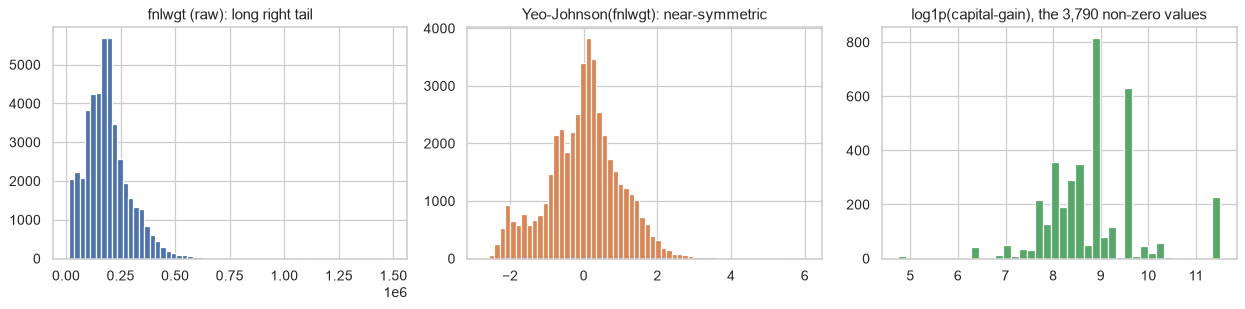

Domain-defined age bands (pd.cut):
{'17-25': 8441, '26-35': 12074, '36-45': 11472, '46-55': 7936, '56-65': 3955, '66+': 1344}
Equal-frequency bins of hours (pd.qcut; duplicates dropped because 40 hours repeats so much):
{Interval(0.999, 40.0, closed='right'): 31445, Interval(40.0, 45.0, closed='right'): 3504, Interval(45.0, 99.0, closed='right'): 10273}


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
axes[0].hist(df["fnlwgt"], bins=60); axes[0].set(title="fnlwgt (raw): long right tail")
axes[1].hist(PowerTransformer("yeo-johnson").fit_transform(df[["fnlwgt"]]).ravel(), bins=60, color="C1"); axes[1].set(title="Yeo-Johnson(fnlwgt): near-symmetric")
nz = df.loc[df["capital-gain"] > 0, "capital-gain"]
axes[2].hist(np.log1p(nz), bins=40, color="C2"); axes[2].set(title=f"log1p(capital-gain), the {len(nz):,} non-zero values")
plt.show()

# Discretisation: equal-width bins vs equal-frequency bins vs domain-defined bins
age_bands = pd.cut(df["age"], bins=[16, 25, 35, 45, 55, 65, 100], labels=["17-25", "26-35", "36-45", "46-55", "56-65", "66+"])
hours_q = pd.qcut(df["hours-per-week"], q=4, duplicates="drop")
print("Domain-defined age bands (pd.cut):"); print(age_bands.value_counts(sort=False).to_dict())
print("Equal-frequency bins of hours (pd.qcut; duplicates dropped because 40 hours repeats so much):"); print(hours_q.value_counts(sort=False).to_dict())

No single transform is best, so *measure* it (skewness table above). For `fnlwgt` the square root (0.20) and especially
Yeo-Johnson (0.02) remove the skew, while `log1p` over-corrects to -0.83; for `hours-per-week` a log makes things *worse*
(-2.20), because that column has no heavy right tail to begin with. `capital-gain` stays skewed (about 3 even after the
best transform) because 92% of its values are exactly 0; a better treatment is a "has any gain" flag plus the transformed
non-zero amounts. Which scaler is right depends on outliers: **min-max** is squeezed by extremes (almost all `fnlwgt` ends
up near 0), **z-score** is also influenced by them, **robust scaling** uses median and IQR and is the most stable.
Remember: *fit* any scaler on the **training** data only, then apply it to the validation/test data (the project does this by
placing it inside a `Pipeline`).

## 3.7 Data encoding

Models need numbers, so categorical attributes must be *encoded*:

| Attribute kind | Encoding | Why |
|---|---|---|
| Binary | 0/1 | two values only |
| Ordinal | integer codes **in the true order** (ordinal encoding) | keeps the order |
| Nominal, few levels | **one-hot** (one 0/1 column per level) | no fake order |
| Nominal, many levels | frequency or target encoding | one-hot would explode the width |
| Target (classification) | label encoding | model output |

In [14]:
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, LabelEncoder
from data import three_way_split

X, y = df.drop(columns=TARGET), df[TARGET]
X_tr, X_va, X_te, y_tr, y_va, y_te = three_way_split(X, y, seed=SEED)

# binary + target
sex01 = (df["sex"] == "Male").astype(int)
le = LabelEncoder().fit(df[TARGET]); y_enc = le.transform(df[TARGET])
print("Target label encoding:", dict(zip(le.classes_, le.transform(le.classes_))), "| sex coded as Male=1:", sex01.mean().round(3))

# ordinal, in the true order -> must reproduce education-num - 1
edu_order = df.groupby("education", observed=True)["education-num"].first().sort_values().index.astype(str).tolist()
oe = OrdinalEncoder(categories=[edu_order]).fit_transform(df[["education"]].astype(str)).ravel()
print("Ordinal encoding of education equals education-num - 1:", bool(np.array_equal(oe, df["education-num"] - 1)))

# nominal: one-hot, and the width it creates
nominal = ["workclass", "marital-status", "occupation", "relationship", "race", "native-country"]
width = pd.Series({c: df[c].nunique() for c in nominal}, name="one-hot columns created")
display(width.to_frame().T)
ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(X_tr[nominal])
print(f"One-hot on the 6 nominal columns: {X_tr[nominal].shape[1]} columns -> {ohe.transform(X_tr[nominal]).shape[1]} columns; "
      f"pd.get_dummies(drop_first=True) would give {pd.get_dummies(X_tr[nominal], drop_first=True).shape[1]} (the dropped level is the 'baseline', avoiding redundancy)")

Target label encoding: {'<=50K': np.int64(0), '>50K': np.int64(1)} | sex coded as Male=1: 0.675
Ordinal encoding of education equals education-num - 1: True


,workclass,marital-status,occupation,relationship,race,native-country
one-hot columns created,7,7,14,6,5,41


One-hot on the 6 nominal columns: 6 columns -> 80 columns; pd.get_dummies(drop_first=True) would give 74 (the dropped level is the 'baseline', avoiding redundancy)


In [15]:
# High-cardinality nominal: frequency encoding and (leak-safe) target encoding of native-country
col = "native-country"
freq = X_tr[col].value_counts(normalize=True)
global_rate = (y_tr == ">50K").mean()
stats_tr = pd.DataFrame({"n": X_tr[col].value_counts(), "rate": (y_tr == ">50K").groupby(X_tr[col], observed=True).mean()})
smooth = 20                                    # shrink small groups toward the global rate
te = ((stats_tr["n"] * stats_tr["rate"] + smooth * global_rate) / (stats_tr["n"] + smooth))

enc = pd.DataFrame({"country": X_va[col].astype(str).values,
                    "frequency enc.": X_va[col].map(freq).astype(float).fillna(0).values,
                    "target enc. (learned from train only)": X_va[col].map(te).astype(float).fillna(global_rate).values})
print(f"Global >50K rate in training data: {global_rate:.3f}; smoothing strength {smooth}")
display(enc.drop_duplicates("country").sort_values("target enc. (learned from train only)").iloc[[0, 1, 2, -3, -2, -1]].round(3))

Global >50K rate in training data: 0.248; smoothing strength 20


,country,frequency enc.,target enc. (learned from train only)
4,Mexico,0.020,0.060
622,Guatemala,0.002,0.084
839,Columbia,0.002,0.088
84,India,0.004,0.389
1317,Taiwan,0.001,0.408
501,France,0.001,0.421


Both compress 41 countries into one numeric column. **Target encoding** uses the label, so it must be computed on the
**training split only** and applied to the others (an unseen or tiny group falls back to the global rate, and the
*smoothing* keeps small groups from getting extreme values); computing it on all the data would leak the answer into the
features. This is the same reason cleaning and encoding steps are fitted inside a `Pipeline` in `src/baseline.py`.